# E0. Motivation: heterogeneity of the vancomycin resistance between hospital units

If the resistance does not change between units (once the specimen type and the patient profile are considered), the spatial context is not relevant and the objective of the paper must be reconsidered.

Outputs: `results/tables/` and `results/figures/`.

In [1]:
import sys
sys.path.insert(0, "..")
import utils
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency
import statsmodels.formula.api as smf
from scipy.stats import chi2
TABLES_PATH = utils.results_path("E0-motivation", "tables")
FIGURES_PATH = utils.results_path("E0-motivation", "figures")

# 1. Reading the datasets

In [2]:
df = utils.read_mining_view("clinical")
df_all = utils.read_mining_view("all-specimens")
df["resistant"] = utils.get_target_mask(df).astype(int)
df_all["resistant"] = utils.get_target_mask(df_all).astype(int)
print("Clinical cultures: " + str(len(df)) + " isolates, resistance rate = " + str(round(df["resistant"].mean(), 3)))
print("All specimens: " + str(len(df_all)) + " isolates, resistance rate = " + str(round(df_all["resistant"].mean(), 3)))

Clinical cultures: 2505 isolates, resistance rate = 0.331
All specimens: 3119 isolates, resistance rate = 0.401


# 2. Resistance rate by unit (cumulative antibiogram by unit)

In [3]:
def rate_table(dataset, attribute):
    rows = []
    for value, group in dataset.groupby(attribute):
        n, r = len(group), int(group["resistant"].sum())
        low, high = utils.wilson_interval(r, n)
        rows.append({attribute : value, "n" : n, "R" : r, "rate" : r / n, "ci95_low" : low, "ci95_high" : high})
    table = pd.DataFrame(rows).sort_values("rate", ascending=False).reset_index(drop=True)
    contingency = pd.crosstab(dataset[attribute], dataset["resistant"])
    statistic, p_value, dof, _ = chi2_contingency(contingency)
    cramers_v = np.sqrt(statistic / (contingency.values.sum() * (min(contingency.shape) - 1)))
    print("Chi-square = " + str(round(statistic, 2)) + ", dof = " + str(dof) + ", p-value = " + "{:.2e}".format(p_value) + ", Cramer's V = " + str(round(cramers_v, 3)))
    return table

In [4]:
table_units = rate_table(df, utils.UNIT_ATTRIBUTE)
table_units.to_csv(TABLES_PATH / "resistance_by_unit.csv", index=False)
table_units.round(3)

Chi-square = 84.12, dof = 5, p-value = 1.15e-16, Cramer's V = 0.183


,icu_when_culture,n,R,rate,ci95_low,ci95_high
0,MICU,731,315,0.431,0.395,0.467
1,CSRU,145,61,0.421,0.343,0.502
2,SICU,423,151,0.357,0.313,0.404
3,NO_ICU,759,213,0.281,0.250,0.314
4,TSICU,239,52,0.218,0.170,0.274
5,CCU,208,37,0.178,0.132,0.236


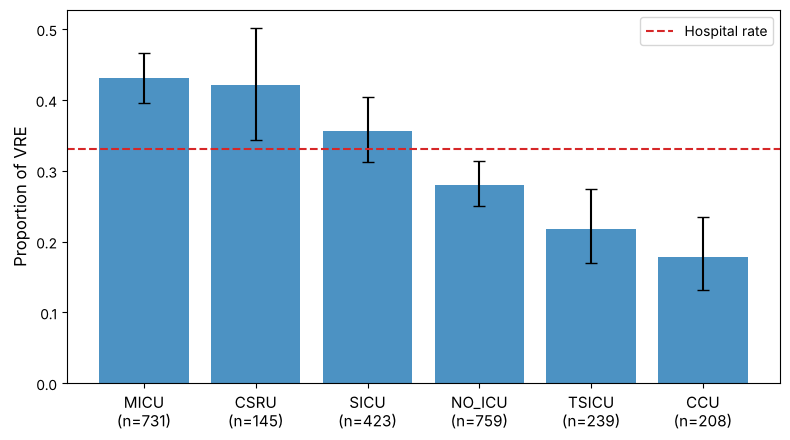

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(table_units))
ax.bar(x, table_units["rate"], color="tab:blue", alpha=0.8)
ax.errorbar(x, table_units["rate"], yerr=[table_units["rate"] - table_units["ci95_low"], table_units["ci95_high"] - table_units["rate"]], fmt="none", color="black", capsize=4)
ax.axhline(df["resistant"].mean(), color="tab:red", linestyle="--", label="Hospital rate")
ax.set_xticks(x)
ax.set_xticklabels([u + "\n(n=" + str(n) + ")" for u, n in zip(table_units[utils.UNIT_ATTRIBUTE], table_units["n"])], fontsize=11)
ax.set_ylabel("Proportion of VRE", fontsize=12)
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_PATH / "resistance_by_unit.pdf")
plt.show()

# 3. Resistance rate by service

In [6]:
table_services = rate_table(df, "service_when_culture")
table_services.to_csv(TABLES_PATH / "resistance_by_service.csv", index=False)
table_services.round(3)

Chi-square = 271.63, dof = 11, p-value = 8.14e-52, Cramer's V = 0.329


,service_when_culture,n,R,rate,ci95_low,ci95_high
0,OMED,76,57,0.750,0.642,0.834
1,SURG,445,194,0.436,0.391,0.482
2,MED,892,373,0.418,0.386,0.451
3,VSURG,61,25,0.410,0.295,0.535
4,CSURG,101,38,0.376,0.288,0.474
5,TSURG,36,9,0.250,0.138,0.411
6,NO_SERVICE,351,78,0.222,0.182,0.269
7,OTHER,39,7,0.179,0.090,0.327
8,CMED,197,29,0.147,0.104,0.203
9,TRAUM,89,9,0.101,0.054,0.181


# 4. Effect of the swabs (screening) on the differences between units

Sensitivity analysis with all the specimens. If the resistance rate of a unit increases a lot when the swabs are included, the differences between units observed with all the specimens are partly due to the screening policy.

In [7]:
df_all["specimen_group"] = np.where(df_all["culture_specimen_type"] == "SWAB", "SWAB", "CLINICAL")
summary = df_all.pivot_table(index=utils.UNIT_ATTRIBUTE, columns="specimen_group", values="resistant", aggfunc=["count", "mean"]).round(3)
summary["rate_all_specimens"] = df_all.groupby(utils.UNIT_ATTRIBUTE)["resistant"].mean().round(3)
summary["rate_clinical_only"] = df.groupby(utils.UNIT_ATTRIBUTE)["resistant"].mean().round(3)
summary.to_csv(TABLES_PATH / "swab_effect_by_unit.csv")
summary

count          mean        rate_all_specimens  \
specimen_group   CLINICAL SWAB CLINICAL   SWAB                      
icu_when_culture                                                    
CCU                   206   10    0.175  0.500              0.190   
CSRU                  140   19    0.407  0.895              0.465   
MICU                  713  119    0.421  0.790              0.474   
NO_ICU                747  107    0.277  0.467              0.301   
SICU                  359  397    0.292  0.743              0.529   
TSICU                 225   77    0.187  0.571              0.285   

                 rate_clinical_only  
specimen_group                       
icu_when_culture                     
CCU                           0.178  
CSRU                          0.421  
MICU                          0.431  
NO_ICU                        0.281  
SICU                          0.357  
TSICU                         0.218

In [8]:
table_units_all = rate_table(df_all, utils.UNIT_ATTRIBUTE)
table_units_all.to_csv(TABLES_PATH / "resistance_by_unit_all_specimens.csv", index=False)
table_units_all.round(3)

Chi-square = 165.26, dof = 5, p-value = 7.48e-34, Cramer's V = 0.23


,icu_when_culture,n,R,rate,ci95_low,ci95_high
0,SICU,756,400,0.529,0.493,0.564
1,MICU,832,394,0.474,0.440,0.508
2,CSRU,159,74,0.465,0.390,0.543
3,NO_ICU,854,257,0.301,0.271,0.333
4,TSICU,302,86,0.285,0.237,0.338
5,CCU,216,41,0.190,0.143,0.247


# 5. Adjusted analysis

Logistic regression of the resistance on the unit, adjusting for the specimen type and the patient attributes. The likelihood-ratio test compares the models with and without the unit.

In [9]:
patient_attributes = [c for c in df.columns if c not in utils.CONTEXT_ATTRIBUTES + [utils.TARGET[0], "resistant"]]
# Attributes with very few 'yes' values are excluded from the regression (quasi-separation).
patient_attributes = [c for c in patient_attributes if df[c].value_counts().min() >= 20]
formula_without_unit = "resistant ~ " + " + ".join("C(" + c + ")" for c in patient_attributes)
formula_with_unit = formula_without_unit + " + C(" + utils.UNIT_ATTRIBUTE + ", Treatment('NO_ICU'))"
model_without_unit = smf.logit(formula_without_unit, data=df).fit(disp=0)
model_with_unit = smf.logit(formula_with_unit, data=df).fit(disp=0)
lr_statistic = 2 * (model_with_unit.llf - model_without_unit.llf)
lr_dof = model_with_unit.df_model - model_without_unit.df_model
print("Patient attributes in the model: " + str(len(patient_attributes)))
print("Likelihood-ratio test of the unit: statistic = " + str(round(lr_statistic, 2)) + ", dof = " + str(int(lr_dof)) + ", p-value = " + "{:.2e}".format(chi2.sf(lr_statistic, lr_dof)))

Patient attributes in the model: 20
Likelihood-ratio test of the unit: statistic = 40.03, dof = 5, p-value = 1.48e-07


In [10]:
unit_terms = [t for t in model_with_unit.params.index if utils.UNIT_ATTRIBUTE in t]
adjusted = pd.DataFrame({
    "adjusted_OR" : np.exp(model_with_unit.params[unit_terms]),
    "ci95_low" : np.exp(model_with_unit.conf_int().loc[unit_terms, 0]),
    "ci95_high" : np.exp(model_with_unit.conf_int().loc[unit_terms, 1]),
    "p_value" : model_with_unit.pvalues[unit_terms],
})
adjusted.index = [t.split("[T.")[-1].rstrip("]") for t in unit_terms]
adjusted.to_csv(TABLES_PATH / "adjusted_odds_ratios_by_unit.csv")
adjusted.round(3) # Reference: NO_ICU.

,adjusted_OR,ci95_low,ci95_high,p_value
CCU,0.593,0.382,0.921,0.020
CSRU,1.782,1.166,2.725,0.008
MICU,1.573,1.225,2.020,0.000
SICU,1.129,0.837,1.522,0.426
TSICU,0.729,0.495,1.075,0.111


# 6. Summary for the paper

- Table: section 2 (rate, 95% CI and n by unit), chi-square and Cramer's V.
- Figure: `results/figures/resistance_by_unit.pdf`.
- Adjusted effect of the unit: section 5 (likelihood-ratio test and adjusted odds ratios).
- Screening effect: section 4 (it justifies the use of clinical cultures in the main analysis).